In [1]:
import xarray as xr
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import numpy as np
import re
import os

# =========================================================
# === 1. CONFIGURACIÓN BASE DEL MAPA
# =========================================================
def setup_map(ax, proj_map, proj_data):
    """Configura el mapa base en un eje Cartopy."""
    ax.coastlines(resolution='110m')
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    ax.add_feature(cfeature.LAND, facecolor='lightgray')


# =========================================================
# === 2. PLOT T2M + Z500
# =========================================================
def plot_temp_z500(ax, lon, lat, temp_field, z500_field,
                   levels_temp, levels_z500,
                   proj_data):

    # --- Temperature filled contours ---
    temp_plot = ax.contourf(
        lon, lat, temp_field,
        levels=levels_temp,
        cmap='bwr',
        extend='both',
        transform=proj_data
    )

    # --- Z500 gray contour lines ---
    c = ax.contour(
        lon, lat, z500_field,
        levels=levels_z500,
        colors='gray',
        linewidths=1.0,
        transform=proj_data
    )

    ax.clabel(
        c,
        fmt='%d',
        fontsize=7,
        colors='gray'
    )

    return temp_plot

# =========================================================
# === 3. PLOT PRECIPITACIÓN
# =========================================================
def plot_precip(ax, lon, lat, precip_field,
                levels_precip, cmap_precip,
                proj_data):

    precip_plot = ax.contourf(
        lon,
        lat,
        precip_field,
        levels=levels_precip,
        cmap=cmap_precip,
        extend='max',
        transform=proj_data
    )

    return precip_plot

def plot_shapefile_mask(ax, lon, lat, mask, color='magenta', lw=2, proj_data=ccrs.PlateCarree()):
    """Plotea un shapefile o mascarilla como contorno."""
    ax.contour(lon, lat, mask, levels=[0.5], colors=color,
               linewidths=lw, transform=proj_data)

# === Normalización de contraste ===
def normalize(band):
    band_min, band_max = np.nanpercentile(band, (2, 98))
    return np.clip((band - band_min) / (band_max - band_min), 0, 1)

import rasterio
from rasterio.windows import from_bounds
from pyproj import Transformer

# === Función para leer GeoTIFF recortado ===
def read_rgb_tiff_crop(tif_path, crop_extent):
    with rasterio.open(tif_path) as src:
        crs = src.crs
        transformer = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
        left, bottom = transformer.transform(crop_extent[0], crop_extent[2])
        right, top = transformer.transform(crop_extent[1], crop_extent[3])

        window = from_bounds(left, bottom, right, top, src.transform)

        r = src.read(1, window=window).astype(float)
        g = src.read(2, window=window).astype(float)
        b = src.read(3, window=window).astype(float)

        transform = src.window_transform(window)
        lon_min, lat_min = crop_extent[0], crop_extent[2]
        lon_max, lat_max = crop_extent[1], crop_extent[3]

    # Normalizar
    r_norm, g_norm, b_norm = normalize(r), normalize(g), normalize(b)
    rgb = np.dstack((r_norm, g_norm, b_norm))

    filename = os.path.basename(tif_path)
    match = re.search(r"(\d{4}-\d{2}-\d{2})", filename)
    fecha = match.group(1) if match else "Fecha desconocida"

    extent = [lon_min, lon_max, lat_min, lat_max]
    return rgb, extent, fecha


In [3]:
from matplotlib.colors import ListedColormap

colors = [
    "#f0f0f0",
    "#7ea6ff",
    "#3366ff",
    "#1e90ff",
    "#00c5cd",
    "#00c878",
    "#32cd32",
    "#9acd32",
    "#ffd54f",
    "#ffb347",
    "#ff7f50",
    "#ff4500",
    "#ff1493",
    "#c050ff",
    "#6a3d9a"
]

cmap_precip = ListedColormap(colors)


In [4]:
filename = '~/ERA5/T2max_daily_anomalies.nc'
t2m = xr.open_dataset(filename)

filename = '~/ERA5/precip_daily_totals.nc'
rrr = xr.open_dataset(filename)

filename = '~//ERA5/Z500_daily_anomalies_75.nc'
z500 = (xr.open_dataset(filename)/9.98).squeeze()


In [5]:
filename = '/home/cr2/cmtorres/ARs_DATA/Global_AR_dataset_Guan.nc'
AR_shape = xr.open_dataset(filename).sel(time=slice('1980-01-01', '2022-12-31'), ens = 1, lev = 0)
AR_shape.coords['lon'] = (AR_shape.coords['lon'] + 180) % 360 - 180
AR_shape = AR_shape.sortby(AR_shape.lon)


In [6]:
filename = '/home/cr2/cmtorres/ARs_DATA/AR_Buffet_1979_2023.nc'
AR_shape_B = xr.open_dataset(filename)
AR_shape_B.coords['lon'] = (AR_shape_B.coords['lon'] + 180) % 360 - 180
AR_shape_B = AR_shape_B.sortby(AR_shape_B.lon)

./fig/map_2019-02-04.png


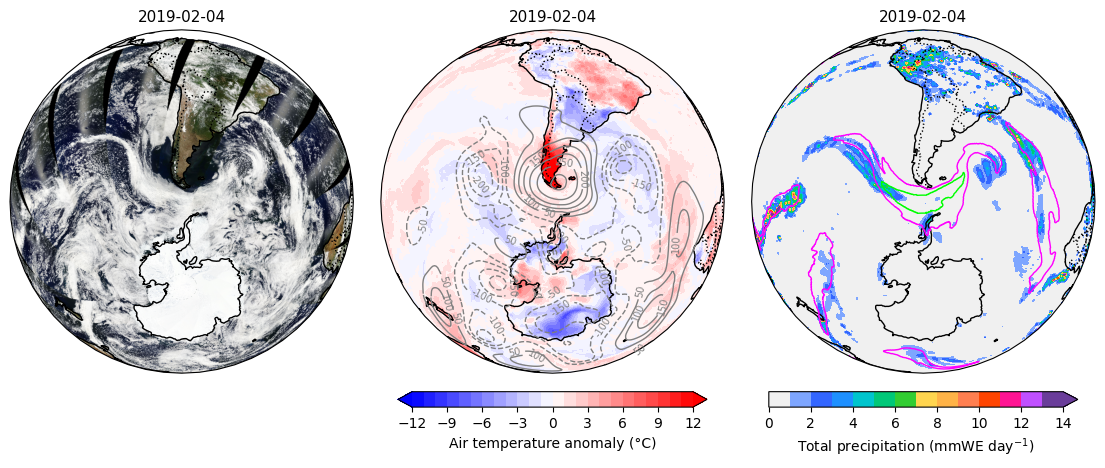

In [15]:
import os
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cartopy.crs as ccrs

# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# Select slice
date_str = "2019-02-04"
t2m_sub = t2m.sel(time=date_str).tmax_anomaly
z500_sub = z500.sel(time=date_str).z_anomaly
rrr_sub = rrr.sel(time=date_str).precip_daily
ar1_sub = AR_shape.sel(time=date_str).shapemap
ar2_sub = AR_shape_B.sel(time=date_str).ar_binary_tag

ar1_sub_12h = ar1_sub.sel(time=(ar1_sub.time.dt.hour == 12))
ar2_sub_12h = ar2_sub.sel(time=(ar2_sub.time.dt.hour == 12))

lon, lat = t2m_sub.longitude, t2m_sub.latitude

levels_temp = np.arange(-12, 13, 1)
levels_z500 = np.delete(np.arange(-300, 301, 50), 6)
levels_precip = np.arange(0, 15, 1.0)

proj_map = ccrs.Orthographic(-70, -60)
proj_data = ccrs.PlateCarree()

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 6),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08},
)

# Panel 1: VIS
setup_map(axes[0], proj_map, proj_data)

tif_path = "/home/cr2/cmtorres/DATA/img_sat_lar/crop_2019-02-04.tif"
crop_extent = [-180, 180, -90, 10]
rgb, extent2, fecha = read_rgb_tiff_crop(tif_path, crop_extent)
axes[0].imshow(rgb, origin="upper", extent=extent2, transform=proj_data)

axes[0].set_title(date_str, fontsize=11)


# Panel 2: Temperature & Z500
setup_map(axes[1], proj_map, proj_data)
temp_plot = plot_temp_z500(
    axes[1],
    lon,
    lat,
    t2m_sub,
    z500_sub,
    levels_temp,
    levels_z500,
    proj_data,
)
axes[1].set_title(date_str, fontsize=11)
fig.colorbar(
    temp_plot,
    ax=axes[1],
    orientation="horizontal",
    pad=0.04,
    shrink=0.9,
    label="Air temperature anomaly (°C)",
)

# Panel 3: Precipitation & AR Shapes
setup_map(axes[2], proj_map, proj_data)
precip_plot = plot_precip(
    axes[2],
    lon,
    lat,
    rrr_sub,#.isel(time=i),
    levels_precip,
    cmap_precip,
    proj_data,
)
axes[2].set_title(date_str, fontsize=11)

ar1_step = ar1_sub_12h.isel(time=0)
ar2_step = ar2_sub_12h.isel(time=0)
mask1 = ar1_step.isnull().astype(int)

plot_shapefile_mask(
    axes[2], ar1_step.lon, ar1_step.lat, mask1, color="magenta", lw=1.0
)
plot_shapefile_mask(
    axes[2], ar2_step.lon, ar2_step.lat, ar2_step, color="lime", lw=1.0
)

fig.colorbar(
    precip_plot,
    ax=axes[2],
    orientation="horizontal",
    pad=0.04,
    shrink=0.9,
    label=r"Total precipitation (mmWE day$^{-1}$)",
)

# Create an invisible colorbar on axes[0] to match layout spacing
cbar_dummy = fig.colorbar(
    temp_plot,  # reuse any ScalarMappable object
    ax=axes[0],
    orientation="horizontal",
    pad=0.04,
    shrink=0.9,
)
cbar_dummy.ax.set_visible(False)  # hide the elements

# Save figure named by date and close to free memory
save_path = os.path.join(output_dir, f"map_{date_str}.png")
print(save_path)
plt.savefig(save_path, dpi=200, bbox_inches="tight")
#plt.close(fig)



./fig/map_2020-02-10.png


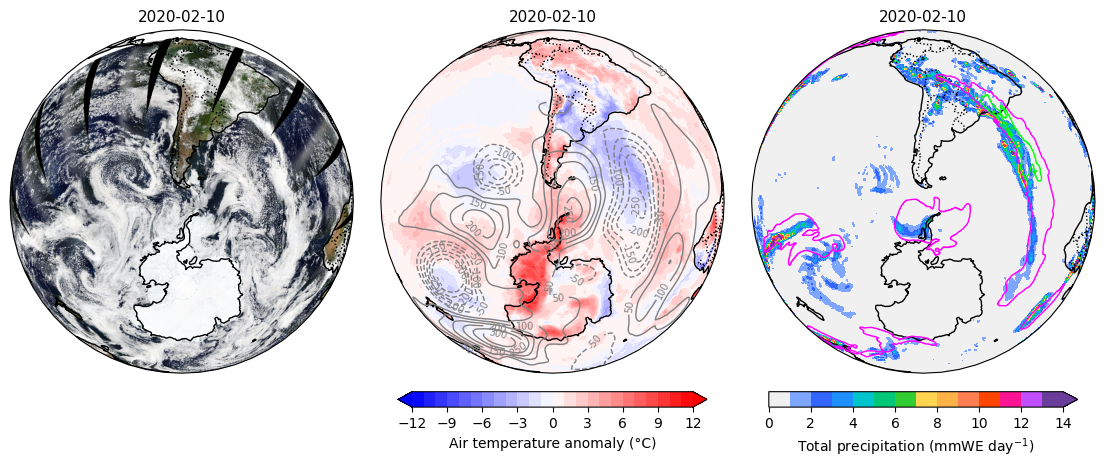

In [16]:
import os
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cartopy.crs as ccrs

# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# Select slice
date_str = "2020-02-10"
t2m_sub = t2m.sel(time=date_str).tmax_anomaly
z500_sub = z500.sel(time=date_str).z_anomaly
rrr_sub = rrr.sel(time=date_str).precip_daily
ar1_sub = AR_shape.sel(time=date_str).shapemap
ar2_sub = AR_shape_B.sel(time=date_str).ar_binary_tag

ar1_sub_12h = ar1_sub.sel(time=(ar1_sub.time.dt.hour == 12))
ar2_sub_12h = ar2_sub.sel(time=(ar2_sub.time.dt.hour == 12))

lon, lat = t2m_sub.longitude, t2m_sub.latitude

levels_temp = np.arange(-12, 13, 1)
levels_z500 = np.delete(np.arange(-300, 301, 50), 6)
levels_precip = np.arange(0, 15, 1.0)

proj_map = ccrs.Orthographic(-70, -60)
proj_data = ccrs.PlateCarree()

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 6),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08},
)

# Panel 1: VIS
setup_map(axes[0], proj_map, proj_data)

tif_path = "/home/cr2/cmtorres/DATA/img_sat_lar/crop_2020-02-10.tif"
crop_extent = [-180, 180, -90, 10]
rgb, extent2, fecha = read_rgb_tiff_crop(tif_path, crop_extent)
axes[0].imshow(rgb, origin="upper", extent=extent2, transform=proj_data)

axes[0].set_title(date_str, fontsize=11)


# Panel 2: Temperature & Z500
setup_map(axes[1], proj_map, proj_data)
temp_plot = plot_temp_z500(
    axes[1],
    lon,
    lat,
    t2m_sub,
    z500_sub,
    levels_temp,
    levels_z500,
    proj_data,
)
axes[1].set_title(date_str, fontsize=11)
fig.colorbar(
    temp_plot,
    ax=axes[1],
    orientation="horizontal",
    pad=0.04,
    shrink=0.9,
    label="Air temperature anomaly (°C)",
)

# Panel 3: Precipitation & AR Shapes
setup_map(axes[2], proj_map, proj_data)
precip_plot = plot_precip(
    axes[2],
    lon,
    lat,
    rrr_sub,#.isel(time=i),
    levels_precip,
    cmap_precip,
    proj_data,
)
axes[2].set_title(date_str, fontsize=11)

ar1_step = ar1_sub_12h.isel(time=0)
ar2_step = ar2_sub_12h.isel(time=0)
mask1 = ar1_step.isnull().astype(int)

plot_shapefile_mask(
    axes[2], ar1_step.lon, ar1_step.lat, mask1, color="magenta", lw=1.0
)
plot_shapefile_mask(
    axes[2], ar2_step.lon, ar2_step.lat, ar2_step, color="lime", lw=1.0
)

fig.colorbar(
    precip_plot,
    ax=axes[2],
    orientation="horizontal",
    pad=0.04,
    shrink=0.9,
    label=r"Total precipitation (mmWE day$^{-1}$)",
)

# Create an invisible colorbar on axes[0] to match layout spacing
cbar_dummy = fig.colorbar(
    temp_plot,  # reuse any ScalarMappable object
    ax=axes[0],
    orientation="horizontal",
    pad=0.04,
    shrink=0.9,
)
cbar_dummy.ax.set_visible(False)  # hide the elements

# Save figure named by date and close to free memory
save_path = os.path.join(output_dir, f"map_{date_str}.png")
print(save_path)
plt.savefig(save_path, dpi=200, bbox_inches="tight")
#plt.close(fig)



./fig/map_2021-02-10.png


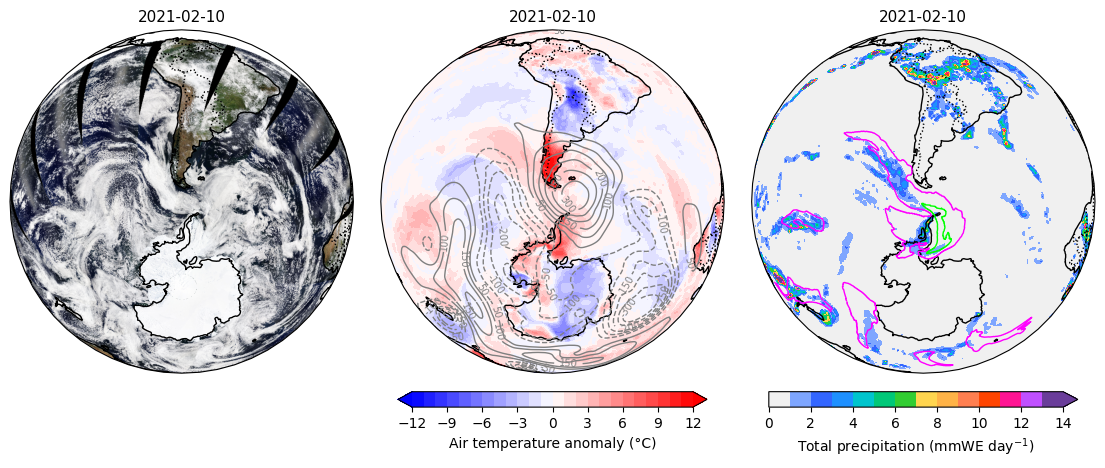

In [17]:
import os
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cartopy.crs as ccrs

# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# Select slice
date_str = "2021-02-10"
t2m_sub = t2m.sel(time=date_str).tmax_anomaly
z500_sub = z500.sel(time=date_str).z_anomaly
rrr_sub = rrr.sel(time=date_str).precip_daily
ar1_sub = AR_shape.sel(time=date_str).shapemap
ar2_sub = AR_shape_B.sel(time=date_str).ar_binary_tag

ar1_sub_12h = ar1_sub.sel(time=(ar1_sub.time.dt.hour == 12))
ar2_sub_12h = ar2_sub.sel(time=(ar2_sub.time.dt.hour == 12))

lon, lat = t2m_sub.longitude, t2m_sub.latitude

levels_temp = np.arange(-12, 13, 1)
levels_z500 = np.delete(np.arange(-300, 301, 50), 6)
levels_precip = np.arange(0, 15, 1.0)

proj_map = ccrs.Orthographic(-70, -60)
proj_data = ccrs.PlateCarree()

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 6),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08},
)

# Panel 1: VIS
setup_map(axes[0], proj_map, proj_data)

tif_path = "/home/cr2/cmtorres/DATA/img_sat_lar/crop_2021-02-10.tif"
crop_extent = [-180, 180, -90, 10]
rgb, extent2, fecha = read_rgb_tiff_crop(tif_path, crop_extent)
axes[0].imshow(rgb, origin="upper", extent=extent2, transform=proj_data)

axes[0].set_title(date_str, fontsize=11)


# Panel 2: Temperature & Z500
setup_map(axes[1], proj_map, proj_data)
temp_plot = plot_temp_z500(
    axes[1],
    lon,
    lat,
    t2m_sub,
    z500_sub,
    levels_temp,
    levels_z500,
    proj_data,
)
axes[1].set_title(date_str, fontsize=11)
fig.colorbar(
    temp_plot,
    ax=axes[1],
    orientation="horizontal",
    pad=0.04,
    shrink=0.9,
    label="Air temperature anomaly (°C)",
)

# Panel 3: Precipitation & AR Shapes
setup_map(axes[2], proj_map, proj_data)
precip_plot = plot_precip(
    axes[2],
    lon,
    lat,
    rrr_sub,#.isel(time=i),
    levels_precip,
    cmap_precip,
    proj_data,
)
axes[2].set_title(date_str, fontsize=11)

ar1_step = ar1_sub_12h.isel(time=0)
ar2_step = ar2_sub_12h.isel(time=0)
mask1 = ar1_step.isnull().astype(int)

plot_shapefile_mask(
    axes[2], ar1_step.lon, ar1_step.lat, mask1, color="magenta", lw=1.0
)
plot_shapefile_mask(
    axes[2], ar2_step.lon, ar2_step.lat, ar2_step, color="lime", lw=1.0
)

fig.colorbar(
    precip_plot,
    ax=axes[2],
    orientation="horizontal",
    pad=0.04,
    shrink=0.9,
    label=r"Total precipitation (mmWE day$^{-1}$)",
)

# Create an invisible colorbar on axes[0] to match layout spacing
cbar_dummy = fig.colorbar(
    temp_plot,  # reuse any ScalarMappable object
    ax=axes[0],
    orientation="horizontal",
    pad=0.04,
    shrink=0.9,
)
cbar_dummy.ax.set_visible(False)  # hide the elements

# Save figure named by date and close to free memory
save_path = os.path.join(output_dir, f"map_{date_str}.png")
print(save_path)
plt.savefig(save_path, dpi=200, bbox_inches="tight")
#plt.close(fig)



./fig/map_2022-02-07.png


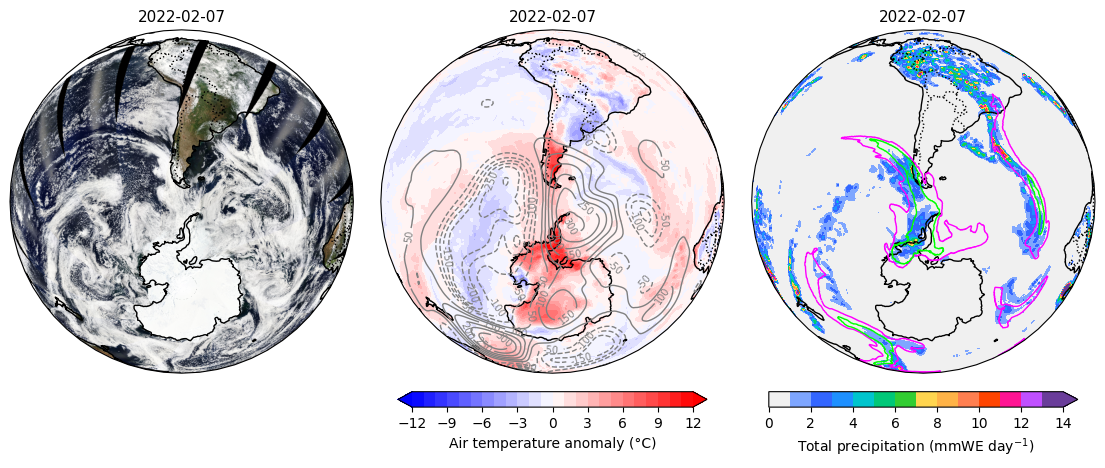

In [18]:
import os
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cartopy.crs as ccrs

# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# Select slice
date_str = "2022-02-07"
t2m_sub = t2m.sel(time=date_str).tmax_anomaly
z500_sub = z500.sel(time=date_str).z_anomaly
rrr_sub = rrr.sel(time=date_str).precip_daily
ar1_sub = AR_shape.sel(time=date_str).shapemap
ar2_sub = AR_shape_B.sel(time=date_str).ar_binary_tag

ar1_sub_12h = ar1_sub.sel(time=(ar1_sub.time.dt.hour == 12))
ar2_sub_12h = ar2_sub.sel(time=(ar2_sub.time.dt.hour == 12))

lon, lat = t2m_sub.longitude, t2m_sub.latitude

levels_temp = np.arange(-12, 13, 1)
levels_z500 = np.delete(np.arange(-300, 301, 50), 6)
levels_precip = np.arange(0, 15, 1.0)

proj_map = ccrs.Orthographic(-70, -60)
proj_data = ccrs.PlateCarree()

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 6),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08},
)

# Panel 1: VIS
setup_map(axes[0], proj_map, proj_data)

tif_path = "/home/cr2/cmtorres/DATA/img_sat_lar/crop_2022-02-07.tif"
crop_extent = [-180, 180, -90, 10]
rgb, extent2, fecha = read_rgb_tiff_crop(tif_path, crop_extent)
axes[0].imshow(rgb, origin="upper", extent=extent2, transform=proj_data)

axes[0].set_title(date_str, fontsize=11)


# Panel 2: Temperature & Z500
setup_map(axes[1], proj_map, proj_data)
temp_plot = plot_temp_z500(
    axes[1],
    lon,
    lat,
    t2m_sub,
    z500_sub,
    levels_temp,
    levels_z500,
    proj_data,
)
axes[1].set_title(date_str, fontsize=11)
fig.colorbar(
    temp_plot,
    ax=axes[1],
    orientation="horizontal",
    pad=0.04,
    shrink=0.9,
    label="Air temperature anomaly (°C)",
)

# Panel 3: Precipitation & AR Shapes
setup_map(axes[2], proj_map, proj_data)
precip_plot = plot_precip(
    axes[2],
    lon,
    lat,
    rrr_sub,#.isel(time=i),
    levels_precip,
    cmap_precip,
    proj_data,
)
axes[2].set_title(date_str, fontsize=11)

ar1_step = ar1_sub_12h.isel(time=0)
ar2_step = ar2_sub_12h.isel(time=0)
mask1 = ar1_step.isnull().astype(int)

plot_shapefile_mask(
    axes[2], ar1_step.lon, ar1_step.lat, mask1, color="magenta", lw=1.0
)
plot_shapefile_mask(
    axes[2], ar2_step.lon, ar2_step.lat, ar2_step, color="lime", lw=1.0
)

fig.colorbar(
    precip_plot,
    ax=axes[2],
    orientation="horizontal",
    pad=0.04,
    shrink=0.9,
    label=r"Total precipitation (mmWE day$^{-1}$)",
)

# Create an invisible colorbar on axes[0] to match layout spacing
cbar_dummy = fig.colorbar(
    temp_plot,  # reuse any ScalarMappable object
    ax=axes[0],
    orientation="horizontal",
    pad=0.04,
    shrink=0.9,
)
cbar_dummy.ax.set_visible(False)  # hide the elements

# Save figure named by date and close to free memory
save_path = os.path.join(output_dir, f"map_{date_str}.png")
print(save_path)
plt.savefig(save_path, dpi=200, bbox_inches="tight")
#plt.close(fig)

